<a href="https://colab.research.google.com/github/SnehithG79/Fine-Tuning-a-VLM-/blob/main/FineTuningVITTransformer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import random
import gc
import time
import warnings
os.environ["WANDB_DISABLED"] = "true"

import numpy as np
import torch
import kagglehub
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from transformers import ViTForImageClassification, ViTImageProcessor, TrainingArguments, Trainer
from peft import LoraConfig, get_peft_model, PeftModel
from transformers import EarlyStoppingCallback

warnings.filterwarnings("ignore")

In [ ]:
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

MODEL_ID = "google/vit-base-patch16-224-in21k"
KAGGLE_DATASET = "tawsifurrahman/covid19-radiography-database"
CLASS_NAMES = ["COVID", "Lung_Opacity", "Normal", "Viral Pneumonia"]
SEED = 42
EPOCHS = 7
BATCH_SIZE = 32
GRAD_ACCUM = 1
LEARNING_RATE = 5e-4
LOGGING_STEPS = 10
EVAL_STEPS = 50
SAVE_STEPS = 50
EVAL_STRATEGY = "steps"
SAVE_STRATEGY = "steps"
METRIC_FOR_BEST_MODEL = "f1_macro"
LOAD_BEST_MODEL_AT_END = True
MAX_GRAD_NORM = 1
WARMUP_RATIO = 0.1
FP16 = True
REMOVE_UNUSED_COLUMNS = False
OUTPUT_DIR = "./output"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

Using device: cuda


In [ ]:
path = kagglehub.dataset_download(KAGGLE_DATASET)
print("Downloaded to:", path)


def find_dataset_root(base, class_names):
    # walk down until we find the folder that directly contains every class folder
    for root, dirs, _ in os.walk(base):
        if all(c in dirs for c in class_names):
            return root
    raise FileNotFoundError(f"No folder containing {class_names} under {base}. Check CLASS_NAMES.")


def list_images(class_dir):
    files = []
    for root, _, names in os.walk(class_dir):
        if "mask" in os.path.relpath(root, class_dir).lower():   # this dataset ships masks next to the images
            continue
        files += [os.path.join(root, n) for n in names if n.lower().endswith((".png", ".jpg", ".jpeg"))]
    return sorted(files)


DATA_DIR = find_dataset_root(path, CLASS_NAMES)
print("Dataset root:", DATA_DIR)

paths, labels = [], []
for label_id, class_name in enumerate(CLASS_NAMES):
    files = list_images(os.path.join(DATA_DIR, class_name))
    random.Random(SEED).shuffle(files)
    files = files[:MAX_PER_CLASS]
    paths += files
    labels += [label_id] * len(files)

# 70% train, 15% validation, 15% test, keeping the class balance in every split
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    paths, labels, test_size=0.30, stratify=labels, random_state=SEED
)
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths, temp_labels, test_size=0.50, stratify=temp_labels, random_state=SEED
)


class ImagePathDataset(torch.utils.data.Dataset):
    def __init__(self, paths, labels):
        self.paths = paths
        self.labels = labels

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        image = Image.open(self.paths[i]).convert("RGB")   # X-rays are grayscale, ViT wants 3 channels
        return {"image": image, "label": self.labels[i]}


train_dataset = ImagePathDataset(train_paths, train_labels)
eval_dataset = ImagePathDataset(val_paths, val_labels)
test_dataset = ImagePathDataset(test_paths, test_labels)

NUM_STEPS = (len(train_dataset) // (BATCH_SIZE * GRAD_ACCUM)) * EPOCHS
print(f"train: {len(train_dataset)} | validation: {len(eval_dataset)} | test: {len(test_dataset)}")
print(f"NUM_STEPS: {NUM_STEPS}")

Using Colab cache for faster access to the 'covid19-radiography-database' dataset.
Downloaded to: /kaggle/input/covid19-radiography-database
Dataset root: /kaggle/input/covid19-radiography-database/COVID-19_Radiography_Dataset
train: 2800 | validation: 600 | test: 600
NUM_STEPS: 609


Images per class (train): {'COVID': 700, 'Lung_Opacity': 700, 'Normal': 700, 'Viral Pneumonia': 700}
------------------------------
Actual label: Lung_Opacity | image size: (299, 299)


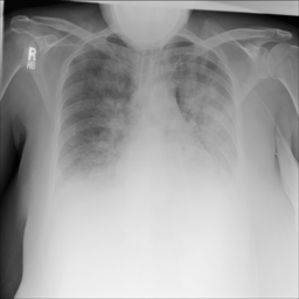

In [ ]:
print("Images per class (train):", dict(zip(CLASS_NAMES, np.bincount(train_labels, minlength=len(CLASS_NAMES)).tolist())))
print("-"*30)

sample_data = test_dataset[0]
sample_image = sample_data["image"]
sample_label = CLASS_NAMES[sample_data["label"]]
print("Actual label:", sample_label, "| image size:", sample_image.size)
sample_image

In [ ]:
id2label = {i: name for i, name in enumerate(CLASS_NAMES)}
label2id = {name: i for i, name in enumerate(CLASS_NAMES)}

image_processor = ViTImageProcessor.from_pretrained(MODEL_ID)   # resize to 224 + normalise, same as pretraining

model = ViTForImageClassification.from_pretrained(
    MODEL_ID,
    num_labels=len(CLASS_NAMES),
    id2label=id2label,
    label2id=label2id,
)   # a new, randomly initialised classification head is added on top of the pretrained ViT
model = model.to(device)

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.weight | UNEXPECTED | 
pooler.dense.bias   | UNEXPECTED | 
classifier.weight   | MISSING    | 
classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
def predict_image(sample_data):
    model.eval()
    inputs = image_processor(images=sample_data["image"], return_tensors="pt")
    inputs = inputs.to(device)

    with torch.no_grad():
        logits = model(**inputs).logits
    probs = torch.softmax(logits, dim=-1)[0]
    del inputs

    predicted_id = int(probs.argmax())
    predicted_label = CLASS_NAMES[predicted_id]
    actual_label = CLASS_NAMES[sample_data["label"]]
    return predicted_label, float(probs[predicted_id]), actual_label


predicted_label, confidence, actual_label = predict_image(sample_data)
print(f"Predicted Label (before fine-tuning): {predicted_label} ({confidence:.2f})")
print(f"Actual Label: {actual_label}")

Predicted Label (before fine-tuning): COVID (0.26)
Actual Label: Lung_Opacity


In [ ]:
peft_config = LoraConfig(
    lora_alpha=16,
    lora_dropout=0.1,
    r=16,
    bias="none",
    target_modules=["q_proj", "v_proj"],   # attention layers, as named in your transformers version
    modules_to_save=["classifier"],   # the new head is random, so train it fully
)

print(f"Before adapter parameters: {model.num_parameters()}")
peft_model = get_peft_model(model, peft_config)
peft_model.print_trainable_parameters()

Before adapter parameters: 85801732
trainable params: 592,900 || all params: 86,394,632 || trainable%: 0.6863


In [ ]:
linear_names = sorted({n.split(".")[-1] for n, m in model.named_modules() if isinstance(m, torch.nn.Linear)})
print(linear_names)

['classifier', 'fc1', 'fc2', 'k_proj', 'o_proj', 'q_proj', 'v_proj']


In [ ]:
WARMUP_STEPS = max(1, int(0.1 * NUM_STEPS))   # 10% of training steps; NUM_STEPS was computed in the data cell
print("Warmup steps:", WARMUP_STEPS)

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    gradient_accumulation_steps=GRAD_ACCUM,
    learning_rate=LEARNING_RATE,
    logging_steps=LOGGING_STEPS,
    eval_steps=EVAL_STEPS,
    eval_strategy=EVAL_STRATEGY,
    save_strategy=SAVE_STRATEGY,
    save_steps=SAVE_STEPS,
    save_total_limit=2,
    metric_for_best_model=METRIC_FOR_BEST_MODEL,
    load_best_model_at_end=LOAD_BEST_MODEL_AT_END,
    max_grad_norm=MAX_GRAD_NORM,
    warmup_steps=WARMUP_STEPS,   # replaces warmup_ratio
    lr_scheduler_type="cosine",
    fp16=FP16,
    remove_unused_columns=REMOVE_UNUSED_COLUMNS,
    label_names=["labels"],
    dataloader_num_workers=2,
    report_to="none",
    seed=SEED,
)


Warmup steps: 60


In [ ]:
collate_sample = [train_dataset[0], train_dataset[1]]   # for batch size 2.


def collate_fn(examples):
    images = [example["image"] for example in examples]
    batch = image_processor(images, return_tensors="pt")
    batch["labels"] = torch.tensor([example["label"] for example in examples])
    return batch


def compute_metrics(eval_pred):
    logits, label_ids = eval_pred
    if isinstance(logits, tuple):
        logits = logits[0]
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(label_ids, preds),
        "f1_macro": f1_score(label_ids, preds, average="macro"),   # fair even when classes are imbalanced
    }


collated_data = collate_fn(collate_sample)
print(collated_data.keys())   # dict_keys(['pixel_values', 'labels'])
print(collated_data["pixel_values"].shape)   # torch.Size([2, 3, 224, 224])

KeysView({'pixel_values': tensor([[[[-0.9294, -0.9294, -0.9294,  ..., -0.7412, -0.2000, -0.0275],
          [-0.9922, -0.9922, -0.9922,  ..., -0.6471, -0.1059, -0.0118],
          [-1.0000, -1.0000, -1.0000,  ..., -0.4902,  0.0824,  0.0824],
          ...,
          [-0.8588, -0.8745, -0.8745,  ..., -0.8902, -0.8667, -0.8667],
          [-0.8588, -0.8745, -0.8824,  ..., -0.8902, -0.8667, -0.8588],
          [-0.7882, -0.8039, -0.8118,  ..., -0.8039, -0.7725, -0.7725]],

         [[-0.9294, -0.9294, -0.9294,  ..., -0.7412, -0.2000, -0.0275],
          [-0.9922, -0.9922, -0.9922,  ..., -0.6471, -0.1059, -0.0118],
          [-1.0000, -1.0000, -1.0000,  ..., -0.4902,  0.0824,  0.0824],
          ...,
          [-0.8588, -0.8745, -0.8745,  ..., -0.8902, -0.8667, -0.8667],
          [-0.8588, -0.8745, -0.8824,  ..., -0.8902, -0.8667, -0.8588],
          [-0.7882, -0.8039, -0.8118,  ..., -0.8039, -0.7725, -0.7725]],

         [[-0.9294, -0.9294, -0.9294,  ..., -0.7412, -0.2000, -0.0275],
    

In [ ]:
trainer = Trainer(
    model=peft_model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    data_collator=collate_fn,
    compute_metrics=compute_metrics,
    callbacks = [EarlyStoppingCallback(early_stopping_patience=3)]
)

In [ ]:
print("-"*30)
print("Initial Evaluation")
metric = trainer.evaluate()
print(metric)
print("-"*30)

print("Training")
trainer.train()
print("-"*30)

------------------------------
Initial Evaluation


Training Loss,Validation Loss,Step,Accuracy,F1 Macro
No log,1.383966,0,0.280000,0.200167


{'eval_loss': 1.3839664459228516, 'eval_accuracy': 0.28, 'eval_f1_macro': 0.20016738003100015}
------------------------------
Training


Step,Training Loss,Validation Loss,Accuracy,F1 Macro
50,1.207961,1.077430,0.693333,0.689838
100,0.557604,0.565892,0.795000,0.792972
150,0.340619,0.401349,0.845000,0.845276
200,0.255581,0.314175,0.883333,0.883035
250,0.153316,0.290612,0.886667,0.885504
300,0.177049,0.244728,0.911667,0.911411
350,0.205350,0.242695,0.913333,0.912963
400,0.125961,0.265229,0.905000,0.904494
450,0.133545,0.209775,0.923333,0.923666
500,0.102190,0.224308,0.928333,0.928627


------------------------------


In [ ]:
trainer.save_model(training_args.output_dir)   # saves only the small LoRA adapter + the trained classifier head
image_processor.save_pretrained(training_args.output_dir)

['./output/preprocessor_config.json']

In [ ]:
print("Test set evaluation")
test_output = trainer.predict(test_dataset)
test_preds = np.argmax(test_output.predictions, axis=-1)

print(classification_report(test_output.label_ids, test_preds, target_names=CLASS_NAMES, zero_division=0))
print(confusion_matrix(test_output.label_ids, test_preds))   # rows = actual class, columns = predicted class

Test set evaluation


                 precision    recall  f1-score   support

          COVID       0.98      0.94      0.96       150
   Lung_Opacity       0.90      0.91      0.90       150
         Normal       0.89      0.89      0.89       150
Viral Pneumonia       0.98      0.99      0.99       150

       accuracy                           0.94       600
      macro avg       0.94      0.93      0.94       600
   weighted avg       0.94      0.94      0.94       600

[[141   4   5   0]
 [  2 137  11   0]
 [  1  12 134   3]
 [  0   0   1 149]]


In [ ]:
base_model = ViTForImageClassification.from_pretrained(
    MODEL_ID,
    num_labels=len(CLASS_NAMES),
    id2label=id2label,
    label2id=label2id,
)
print(f"Before adapter parameters: {base_model.num_parameters()}")
model = PeftModel.from_pretrained(base_model, OUTPUT_DIR)   # loads the saved LoRA adapter + classifier head
model = model.to(device)
print(f"After adapter parameters: {model.num_parameters()}")

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.weight | UNEXPECTED | 
pooler.dense.bias   | UNEXPECTED | 
classifier.weight   | MISSING    | 
classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Before adapter parameters: 85801732
After adapter parameters: 86394632


In [ ]:
predicted_label, confidence, actual_label = predict_image(sample_data)
print(f"Predicted Label (after fine-tuning): {predicted_label} ({confidence:.2f})")
print(f"Actual Label: {actual_label}")

Predicted Label (after fine-tuning): Lung_Opacity (0.99)
Actual Label: Lung_Opacity
